# Lab 3

Hagamos algunos ejercicios con pandas, usemos el mismo que el 1_lab3 por probar

In [25]:
import numpy as np
import pandas as pd

df = pd.read_csv("../media/1_lab3/avocado.csv")
df.head()

,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


In [16]:
df.describe()

,Unnamed: 0,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,year
count,18249.000000,18249.000000,1.824900e+04,1.824900e+04,1.824900e+04,1.824900e+04,1.824900e+04,1.824900e+04,1.824900e+04,18249.000000,18249.000000
mean,24.232232,1.405978,8.506440e+05,2.930084e+05,2.951546e+05,2.283974e+04,2.396392e+05,1.821947e+05,5.433809e+04,3106.426507,2016.147899
std,15.481045,0.402677,3.453545e+06,1.264989e+06,1.204120e+06,1.074641e+05,9.862424e+05,7.461785e+05,2.439660e+05,17692.894652,0.939938
min,0.000000,0.440000,8.456000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,2015.000000
25%,10.000000,1.100000,1.083858e+04,8.540700e+02,3.008780e+03,0.000000e+00,5.088640e+03,2.849420e+03,1.274700e+02,0.000000,2015.000000
50%,24.000000,1.370000,1.073768e+05,8.645300e+03,2.906102e+04,1.849900e+02,3.974383e+04,2.636282e+04,2.647710e+03,0.000000,2016.000000
75%,38.000000,1.660000,4.329623e+05,1.110202e+05,1.502069e+05,6.243420e+03,1.107834e+05,8.333767e+04,2.202925e+04,132.500000,2017.000000
max,52.000000,3.250000,6.250565e+07,2.274362e+07,2.047057e+07,2.546439e+06,1.937313e+07,1.338459e+07,5.719097e+06,551693.650000,2018.000000


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  str    
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  str    
 12  year          18249 non-null  int64  
 13  region        18249 non-null  str    
dtypes: float64(9), int64(2), str(3)
memory usage: 1.9 MB


Veamos si existen nulos (NAN). El método isna() crea un dataframe booleano, con True donde hay valores nulos. Con el método sum() sumamos por cada categoría (True -> 1, False -> 0).

In [10]:
df.isna().sum()

Unnamed: 0      0
Date            0
AveragePrice    0
Total Volume    0
4046            0
4225            0
4770            0
Total Bags      0
Small Bags      0
Large Bags      0
XLarge Bags     0
type            0
year            0
region          0
dtype: int64

Convertimos fecha en índice

In [26]:
df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace = True)

/tmp/ipykernel_44047/1009093409.py:2: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index("Date", inplace = True)


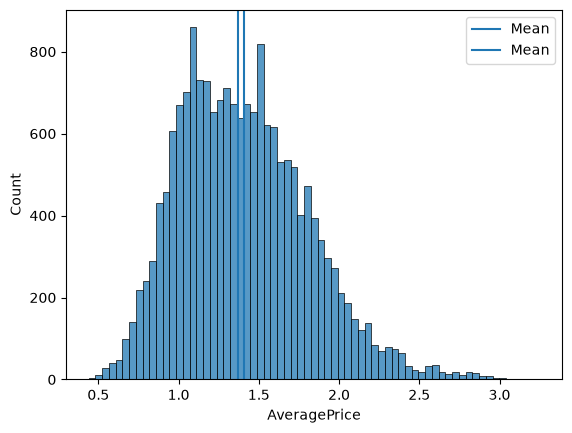

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(x = df["AveragePrice"])
plt.axvline(x = df["AveragePrice"].mean(), label = "Mean")
plt.axvline(x = df["AveragePrice"].median(), label = "Mean")

plt.legend()

              AveragePrice  Total Volume
AveragePrice      1.000000     -0.192752
Total Volume     -0.192752      1.000000


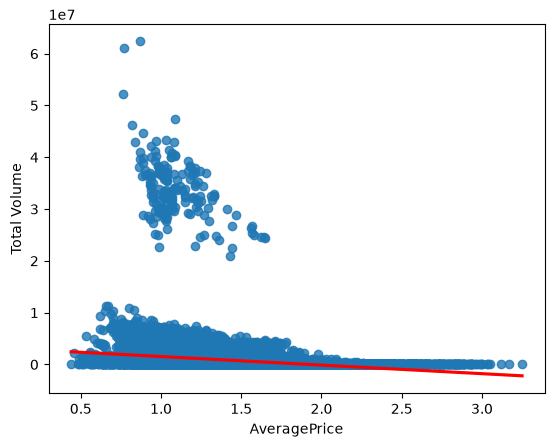

In [45]:
corr = df[["AveragePrice", "Total Volume"]].corr()

sns.regplot(x = "AveragePrice", y = "Total Volume", data = df, line_kws = {"color": "red"})
print(corr)

In [50]:
df = pd.read_excel("../media/ventas_helados.xlsx")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1393 entries, 0 to 1392
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fecha            1393 non-null   datetime64[us]
 1   id_producto      1393 non-null   int64         
 2   ventas_unidades  1393 non-null   int64         
 3   precio           1317 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(2)
memory usage: 43.7 KB


In [53]:
df.describe()

,fecha,id_producto,ventas_unidades,precio
count,1393,1393.000000,1393.000000,1317.000000
mean,2019-11-29 06:45:13.567839,3907.051687,2762.432161,2.831678
min,2019-01-07 00:00:00,17.000000,0.000000,1.430000
25%,2019-06-03 00:00:00,402.000000,274.000000,2.390000
50%,2019-11-04 00:00:00,4468.000000,986.000000,2.530000
75%,2020-05-25 00:00:00,6525.000000,4780.000000,3.040000
max,2020-12-28 00:00:00,9134.000000,95300.000000,5.310000
std,NaN,3128.919927,4136.880270,0.901526


Veamos los nulos

In [51]:
df[df["precio"].isna()]

,fecha,id_producto,ventas_unidades,precio
15,2019-01-07,7118,0,NaN
31,2019-01-14,7118,0,NaN
47,2019-01-21,7118,0,NaN
63,2019-01-28,7118,0,NaN
79,2019-02-04,7118,0,NaN
...,...,...,...,...
1051,2020-05-25,7118,0,NaN
1062,2020-06-01,7118,0,NaN
1073,2020-06-08,7118,0,NaN
1084,2020-06-15,7118,0,NaN


Pongamos la media.

In [62]:
df = df.fillna({"precio": df.precio.median()})

Vemos que ya no hay nulos.

In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1393 entries, 0 to 1392
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fecha            1393 non-null   datetime64[us]
 1   id_producto      1393 non-null   int64         
 2   ventas_unidades  1393 non-null   int64         
 3   precio           1393 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(2)
memory usage: 43.7 KB


In [66]:
df.id_producto.value_counts()

id_producto
17      103
9134    103
8689    103
402     103
2033    103
240     103
5684    103
101     103
3636    103
5019    103
7118    103
4758     52
4577     52
6525     52
999      52
4468     52
Name: count, dtype: int64

Parece que el máximo de unidades vendidas es un outlier, veámoslo

<Axes: ylabel='ventas_unidades'>

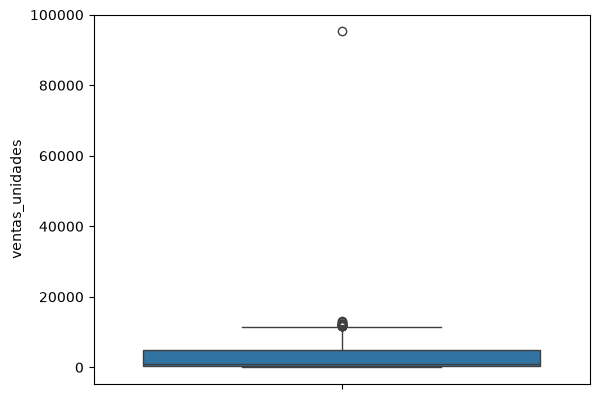

In [67]:
sns.boxplot(df.ventas_unidades)

En efecto parece un outlier. Primero, normalizemos

In [73]:
ventas_stats = (df.ventas_unidades.mean(), df.ventas_unidades.std())
df = df.assign(z = lambda x: (x.ventas_unidades - ventas_stats[0]) / ventas_stats[1])
df.loc[df.ventas_unidades == df.ventas_unidades.max()].z

104    22.368926
Name: z, dtype: float64

El valor se encuentra a 22 desviaciones estándar!

In [82]:
df.loc[df.ventas_unidades == df.ventas_unidades.max()].ventas_unidades = df.loc[df.ventas_unidades == df.ventas_unidades.max()].ventas_unidades / 10 

In [83]:
df.describe()

,fecha,id_producto,ventas_unidades,precio,z
count,1393,1393.000000,1393.000000,1393.000000,1.393000e+03
mean,2019-11-29 06:45:13.567839,3907.051687,2762.432161,2.815219,3.825607e-17
min,2019-01-07 00:00:00,17.000000,0.000000,1.430000,-6.677573e-01
25%,2019-06-03 00:00:00,402.000000,274.000000,2.400000,-6.015239e-01
50%,2019-11-04 00:00:00,4468.000000,986.000000,2.530000,-4.294135e-01
75%,2020-05-25 00:00:00,6525.000000,4780.000000,3.000000,4.877027e-01
max,2020-12-28 00:00:00,9134.000000,95300.000000,5.310000,2.236893e+01
std,NaN,3128.919927,4136.880270,0.879246,1.000000e+00


<Axes: ylabel='ventas_unidades'>

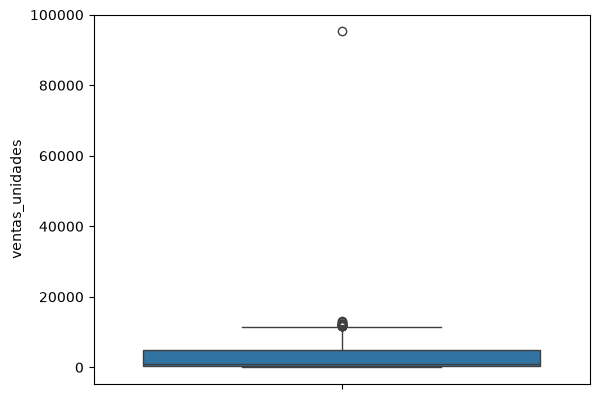

In [75]:
sns.boxplot(df.ventas_unidades)